In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
def calculate_percentage_from_excel(file_path, dp_videos, human_videos, columns_to_analyze):
    # Load the Excel file
    xls = pd.ExcelFile(file_path)
    
    # Load the first sheet into a dataframe
    df = pd.read_excel(xls, sheet_name='Sheet0')

    # Function to classify the response into 'DP', 'human', or '비슷하다'
    def classify_response(response):
        if '비슷' in response:  # '비슷' as a substring counts as '비슷하다'
            return 'similar'
        elif any(video in response for video in dp_videos):
            return 'DP'
        elif any(video in response for video in human_videos):
            return 'human'
        return 'Unknown'

    # Initialize dictionaries to store both percentages and counts
    percentage_data = {'DP': [], 'human': [], 'similar': []}
    count_data = {'DP': [], 'human': [], 'similar': []}

    # Iterate through each column and classify the responses
    for column in columns_to_analyze:
        df[column] = df[column].astype(str)  # Convert to string for processing
        print(df[column] )
        df[column + '_classification'] = df[column].apply(classify_response)
        
        # Calculate counts for each category
        column_counts = {
            'DP': (df[column + '_classification'] == 'DP').sum(),
            'human': (df[column + '_classification'] == 'human').sum(),
            'similar': (df[column + '_classification'] == 'similar').sum()
        }
        total_responses_column = sum(column_counts.values())

        # Store counts
        count_data['DP'].append(column_counts['DP'])
        count_data['human'].append(column_counts['human'])
        count_data['similar'].append(column_counts['similar'])
        # Calculate percentages for each column and store them
        if total_responses_column > 0:
            percentage_data['DP'].append((column_counts['DP'] / total_responses_column) * 100)
            percentage_data['human'].append((column_counts['human'] / total_responses_column) * 100)
            percentage_data['similar'].append((column_counts['similar'] / total_responses_column) * 100)
        else:
            percentage_data['DP'].append(0)
            percentage_data['human'].append(0)
            percentage_data['similar'].append(0)
    
    # Return both percentage and count data
    return percentage_data, count_data


In [3]:

# Mapping videos to DP and human categories (based on the image you shared)
dp_videos = ['A', 'H','M', 'G', 'C','L', 'B', 'E', 'D', 'J']
human_videos = ['F', 'O', 'N', 'S', 'I', 'Z', 'K', 'R', 'Q', 'P']

# Columns to analyze (from the dataset)
ver1_q = ['Q13', 'Q30', 'Q17', 'Q21', 'Q35']
ver2_q = ['Q13', 'Q30', 'Q17', 'Q21', 'Q35']

file_path1 = 'ver1.xlsx'
file_path2 = 'ver2.xlsx'
# Call the function and return the percentage data
percentage_data1, count_data1 = calculate_percentage_from_excel(file_path1, dp_videos, human_videos, ver1_q)
percentage_data2, count_data2 = calculate_percentage_from_excel(file_path2, dp_videos, human_videos, ver2_q)


0     어떤 하이라이트를 더 선호하십니까? \n\n*영상 순서가 섞여 있으니 이름에 유의해...
1                                                  영상 A
2                                                  영상 A
3                                                  영상 A
4                                                  영상 A
5                                                  영상 A
6                                                  영상 F
7                                                  영상 A
8                                                  영상 A
9                                                  영상 F
10                                            비슷하게 선호한다
11                                                 영상 A
12                                                 영상 A
13                                                 영상 A
14                                                 영상 A
15                                                 영상 F
16                                                 영상 A
17                                              

/source/ms/env/highlight/lib/python3.8/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/source/ms/env/highlight/lib/python3.8/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [4]:
count_data1

{'DP': [21, 19, 7, 11, 7],
 'human': [6, 5, 19, 8, 18],
 'similar': [3, 6, 4, 11, 5]}

In [5]:
count_data2

{'DP': [9, 11, 16, 22, 9],
 'human': [12, 11, 11, 7, 11],
 'similar': [9, 8, 3, 1, 10]}

In [6]:
percentage_data2

{'DP': [30.0, 36.666666666666664, 53.333333333333336, 73.33333333333333, 30.0],
 'human': [40.0,
  36.666666666666664,
  36.666666666666664,
  23.333333333333332,
  36.666666666666664],
 'similar': [30.0,
  26.666666666666668,
  10.0,
  3.3333333333333335,
  33.33333333333333]}

In [7]:
dp_values = percentage_data1['DP'] + percentage_data2['DP']
human_values = percentage_data1['human'] + percentage_data2['human']
similar_values = percentage_data1['similar'] + percentage_data2['similar']

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


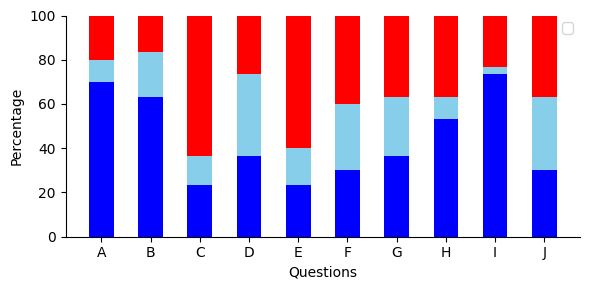

In [8]:
# Create labels for the x-axis (A to J)
labels = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J']

# Plotting
fig, ax = plt.subplots(figsize=(6, 3))  # Increased width to accommodate 10 bars

bar_width = 0.5  # Adjust the bar width

# Plot the DP part of the bar
rects1 = ax.bar(labels, dp_values, width=bar_width, color='blue')  # Sky blue

# Plot the 비슷하다 part of the bar (stacked on top of DP)
rects2 = ax.bar(labels, similar_values, width=bar_width, bottom=dp_values,  color='#87CEEB')  # Orange

# Plot the human part of the bar (stacked on top of 비슷하다)
rects3 = ax.bar(labels, human_values, width=bar_width, bottom=np.array(dp_values) + np.array(similar_values), color='red')  # Green

# Add some text for labels, title, and custom x-axis tick labels, etc.
ax.set_xlabel('Questions')
ax.set_ylabel('Percentage')
# ax.set_title('Preference Distribution Between DP, Similar, and Human')
ax.set_ylim(0, 100)
ax.legend()

# Display percentages on the bars
# for i, (dp, similar, human) in enumerate(zip(dp_values, similar_values, human_values)):
#     ax.text(i, dp / 2, f'{dp:.1f}%', ha='center', color='white', fontweight='bold')  # DP
#     ax.text(i, dp + similar / 2, f'{similar:.1f}%', ha='center', color='white', fontweight='bold')  # Similar
#     ax.text(i, dp + similar + human / 2, f'{human:.1f}%', ha='center', color='white', fontweight='bold')  # Human

# Remove top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Adjust bar width and layout
plt.tight_layout()
plt.show()

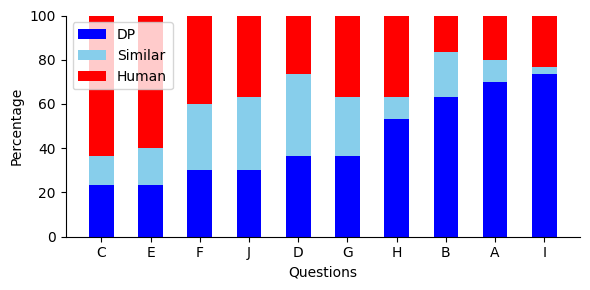

In [9]:
# Combine the data into a list of tuples for sorting
combined_data = list(zip(labels, dp_values, similar_values, human_values))

# Sort the combined data based on dp_values (index 1)
sorted_data = sorted(combined_data, key=lambda x: x[1])

# Unpack the sorted data
sorted_labels, sorted_dp_values, sorted_similar_values, sorted_human_values = zip(*sorted_data)

# Plotting
fig, ax = plt.subplots(figsize=(6, 3))  # Increased width to accommodate 10 bars

bar_width = 0.5  # Adjust the bar width

# Plot the DP part of the bar
rects1 = ax.bar(sorted_labels, sorted_dp_values, width=bar_width, label='DP', color='blue')  # Sky blue

# Plot the 비슷하다 part of the bar (stacked on top of DP)
rects2 = ax.bar(sorted_labels, sorted_similar_values, width=bar_width, bottom=sorted_dp_values, label='Similar', color='#87CEEB')  # Orange

# Plot the human part of the bar (stacked on top of 비슷하다)
rects3 = ax.bar(sorted_labels, sorted_human_values, width=bar_width, bottom=np.array(sorted_dp_values) + np.array(sorted_similar_values), label='Human', color='red')  # Green

# Add some text for labels, title, and custom x-axis tick labels, etc.
ax.set_xlabel('Questions')
ax.set_ylabel('Percentage')
# ax.set_title('Preference Distribution Between DP, Similar, and Human')
ax.set_ylim(0, 100)
ax.legend()

# Display percentages on the bars (optional)
# for i, (dp, similar, human) in enumerate(zip(sorted_dp_values, sorted_similar_values, sorted_human_values)):
#     ax.text(i, dp / 2, f'{dp:.1f}%', ha='center', color='white', fontweight='bold')  # DP
#     ax.text(i, dp + similar / 2, f'{similar:.1f}%', ha='center', color='white', fontweight='bold')  # Similar
#     ax.text(i, dp + similar + human / 2, f'{human:.1f}%', ha='center', color='white', fontweight='bold')  # Human

# Remove top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Adjust bar width and layout
plt.tight_layout()
plt.show()

In [10]:
dp_count = count_data1['DP'] + count_data2['DP']
human_count = count_data1['human'] + count_data2['human']
similar_count = count_data1['similar'] + count_data2['similar']

In [11]:
print(dp_count )
print(human_count)
print(similar_count)

[21, 19, 7, 11, 7, 9, 11, 16, 22, 9]
[6, 5, 19, 8, 18, 12, 11, 11, 7, 11]
[3, 6, 4, 11, 5, 9, 8, 3, 1, 10]


In [12]:
# Combine the data into a list of tuples for sorting
combined_data = list(zip(labels, dp_count, human_count, similar_count))

# Sort the combined data based on dp_values (index 1)
sorted_data = sorted(combined_data, key=lambda x: x[1])

# Unpack the sorted data
sorted_labels, sorted_dp_values, sorted_similar_values, sorted_human_values = zip(*sorted_data)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


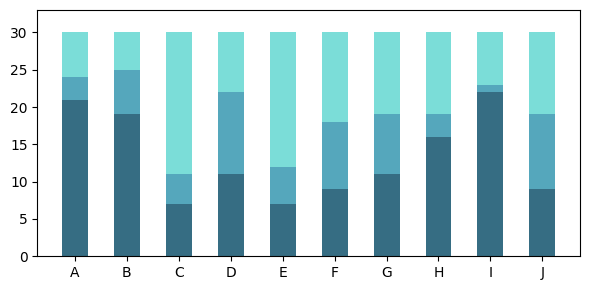

In [13]:
# 라벨 설정
labels = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J']
# 그래프 설정
fig, ax = plt.subplots(figsize=(6, 3))
# 색상 설정 (더 조화로운 색상 조합)
colors = ['#366D83', '#55A7BC', '#7BDDD8']
# 막대 폭 설정 (0.5로 설정하여 더 좁게 만듦)
bar_width = 0.5
# x 위치 조정
x = np.arange(len(labels))
# 누적 막대 그리기
ax.bar(x, dp_count, bar_width,  color=colors[0])
ax.bar(x, similar_count, bar_width, bottom=dp_count,  color=colors[1])
ax.bar(x, human_count, bar_width, bottom=np.array(dp_count) + np.array(similar_count), color=colors[2])

# ax.bar(x, sorted_dp_values, bar_width,  color=colors[0])
# ax.bar(x, sorted_similar_values, bar_width, bottom=sorted_dp_values,  color=colors[1])
# ax.bar(x, sorted_human_values, bar_width, bottom=np.array(sorted_dp_values) + np.array(sorted_similar_values), color=colors[2])


# ax.bar(x, dp_count, bar_width,  color=colors[0])
# ax.bar(x, human_count, bar_width, bottom=dp_count,  color=colors[1])
# ax.bar(x, similar_count, bar_width, bottom=np.array(dp_count) + np.array(human_count), color=colors[2])
# 그래프 꾸미기
# ax.set_ylabel('Vote Count')
# ax.set_title('Comparison of Video Highlight Generation Methods')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend(loc='upper right')
# y축 최대값 설정 (모든 막대의 최대 높이보다 조금 더 높게)
max_height = max(np.array(dp_count) + np.array(human_count) + np.array(similar_count))
ax.set_ylim(0, max_height * 1.1)
# 각 막대 위에 총 투표수 표시
# for i, total in enumerate(np.array(dp_count) + np.array(human_count) + np.array(similar_count)):
#     ax.text(i, total, f'{total}', ha='center', va='bottom')
ax.legend().set_visible(False)
plt.tight_layout()
plt.show()

In [14]:
a = dp_count 
b = human_count
c = similar_count


In [15]:
import numpy as np
from scipy import stats

def chi_square_test_with_posthoc(data_a, data_b, data_c):
    observed = np.array([data_a, data_b, data_c])
    n = sum(observed)
    expected = np.array([n/3, n/3, n/3])
    
    chi2, p_value = stats.chisquare(observed, f_exp=expected)
    
    # 표준화 잔차 계산
    residuals = (observed - expected) / np.sqrt(expected)
    
    # 유의미한 잔차 찾기 (절대값이 1.96보다 큰 경우, 이는 약 95% 신뢰구간에 해당)
    significant_residuals = [('a', residuals[0]), ('b', residuals[1]), ('c', residuals[2])]
    significant_residuals = [(method, res) for method, res in significant_residuals if abs(res) > 1.96]
    
    return chi2, p_value, significant_residuals



# 각 데이터 포인트에 대해 검정 수행
results = []
for i in range(10):
    chi2, p_value, significant_residuals = chi_square_test_with_posthoc(a[i], b[i], c[i])
    significance = "유의미함" if p_value < 0.05 else "유의미하지 않음"
    results.append((i+1, chi2, p_value, significance, significant_residuals))

# 결과 출력
print("데이터 포인트 | 카이제곱 통계량 | p-값    | 유의성 (α=0.05) | 유의미한 차이")
print("-" * 90)
for result in results:
    significant_pairs = ", ".join([f"{method}({res:.2f})" for method, res in result[4]])
    print(f"{result[0]:14d} | {result[1]:16.4f} | {result[2]:.4f} | {result[3]:17} | {significant_pairs}")

# 전체 데이터에 대한 검정
total_a = sum(a)
total_b = sum(b)
total_c = sum(c)
chi2_total, p_value_total, significant_residuals_total = chi_square_test_with_posthoc(total_a, total_b, total_c)
significance_total = "유의미함" if p_value_total < 0.05 else "유의미하지 않음"

print("\n전체 데이터에 대한 검정 결과:")
print(f"카이제곱 통계량: {chi2_total:.4f}")
print(f"p-값: {p_value_total:.4f}")
print(f"유의성 (α=0.05): {significance_total}")
if significant_residuals_total:
    print("유의미한 차이가 있는 방법:")
    for method, res in significant_residuals_total:
        print(f"  {method}: 표준화 잔차 = {res:.2f}")
else:
    print("유의미한 차이를 보이는 특정 방법이 없습니다.")

데이터 포인트 | 카이제곱 통계량 | p-값    | 유의성 (α=0.05) | 유의미한 차이
------------------------------------------------------------------------------------------
             1 |          18.6000 | 0.0001 | 유의미함              | a(3.48), c(-2.21)
             2 |          12.2000 | 0.0022 | 유의미함              | a(2.85)
             3 |          12.6000 | 0.0018 | 유의미함              | b(2.85)
             4 |           0.6000 | 0.7408 | 유의미하지 않음          | 
             5 |           9.8000 | 0.0074 | 유의미함              | b(2.53)
             6 |           0.6000 | 0.7408 | 유의미하지 않음          | 
             7 |           0.6000 | 0.7408 | 유의미하지 않음          | 
             8 |           8.6000 | 0.0136 | 유의미함              | c(-2.21)
             9 |          23.4000 | 0.0000 | 유의미함              | a(3.79), c(-2.85)
            10 |           0.2000 | 0.9048 | 유의미하지 않음          | 

전체 데이터에 대한 검정 결과:
카이제곱 통계량: 26.8800
p-값: 0.0000
유의성 (α=0.05): 유의미함
유의미한 차이가 있는 방법:
  a: 표준화 잔차 = 3.20
  c: 표준화 잔차 = -4.00


In [16]:
b =dp_values

In [17]:
a =human_values

In [18]:
c = similar_values

In [19]:
dp_cnt_values = count_data1['DP'] + count_data2['DP']
human_cnt_values = count_data1['human'] + count_data2['human']
similar_cnt_values = count_data1['similar'] + count_data2['similar']

In [20]:
import pandas as pd
import numpy as np
from scipy import stats

def calculate_counts_from_excel(file_path, dp_videos, human_videos, columns_to_analyze):
    xls = pd.ExcelFile(file_path)
    df = pd.read_excel(xls, sheet_name='Sheet0')
    
    def classify_response(response):
        if '비슷' in response:
            return 'similar'
        elif any(video in response for video in dp_videos):
            return 'DP'
        elif any(video in response for video in human_videos):
            return 'human'
        return 'unknown'
    
    counts = {'DP': 0, 'human': 0, 'similar': 0}
    for column in columns_to_analyze:
        df[column] = df[column].astype(str)
        column_counts = df[column].apply(classify_response).value_counts()
        counts['DP'] += column_counts.get('DP', 0)
        counts['human'] += column_counts.get('human', 0)
        counts['similar'] += column_counts.get('similar', 0)
    
    return counts

# Setup
dp_videos = ['A', 'H', 'M', 'G', 'C', 'L', 'B', 'E', 'D', 'J']
human_videos = ['F', 'O', 'N', 'S', 'I', 'Z', 'K', 'R', 'Q', 'P']
ver1_q = ['Q13', 'Q30', 'Q17', 'Q21', 'Q35']
ver2_q = ['Q13', 'Q30', 'Q17', 'Q21', 'Q35']

file_path1 = 'ver1.xlsx'
file_path2 = 'ver2.xlsx'

# Calculate counts
counts1 = calculate_counts_from_excel(file_path1, dp_videos, human_videos, ver1_q)
counts2 = calculate_counts_from_excel(file_path2, dp_videos, human_videos, ver2_q)

# Combine counts
total_counts = {k: counts1[k] + counts2[k] for k in counts1}

# Perform Chi-square test
observed = np.array([total_counts['DP'], total_counts['human'], total_counts['similar']])
expected = np.sum(observed) / 3  # Equal expectation for each category

chi2, p_value = stats.chisquare(observed, f_exp=[expected, expected, expected])

print("Chi-square Test Results:")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"p-value: {p_value:.4f}")

# Interpretation
alpha = 0.05
print("\nInterpretation:")
if p_value < alpha:
    print("There is a significant difference in preferences among DP, human, and similar categories.")
else:
    print("There is no significant difference in preferences among DP, human, and similar categories.")

# Post-hoc analysis: standardized residuals
residuals = (observed - expected) / np.sqrt(expected)
categories = ['DP', 'human', 'similar']

print("\nStandardized Residuals:")
for category, residual in zip(categories, residuals):
    print(f"{category}: {residual:.4f}")
    if abs(residual) > 1.96:  # 95% confidence level
        print(f"  Significant deviation for {category}")

Chi-square Test Results:
Chi-square statistic: 26.8800
p-value: 0.0000

Interpretation:
There is a significant difference in preferences among DP, human, and similar categories.

Standardized Residuals:
DP: 3.2000
  Significant deviation for DP
human: 0.8000
similar: -4.0000
  Significant deviation for similar


/source/ms/env/highlight/lib/python3.8/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/source/ms/env/highlight/lib/python3.8/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [21]:
a = dp_cnt_values
b = human_cnt_values
c= similar_cnt_values

In [22]:
# 1. Shapiro-Wilk Normality Test
print("Shapiro-Wilk Normality Test:")
for group, data in zip(['A', 'B', 'C'], [a, b, c]):
    stat, p = stats.shapiro(data)
    print(f"Group {group}: W = {stat:.4f}, p-value = {p:.4f}")

# 2. One-way ANOVA
# 데이터 준비
df = pd.DataFrame({
    'value': a + b + c,
    'group': ['A']*10 + ['B']*10 + ['C']*10
})

# ANOVA 수행
f_statistic, p_value = stats.f_oneway(a, b, c)

print("\nOne-way ANOVA results:")
print(f"F-statistic: {f_statistic:.4f}")
print(f"p-value: {p_value:.4f}")

# 3. 사후 검정 (Tukey's HSD)
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey = pairwise_tukeyhsd(df['value'], df['group'])
print("\nTukey's HSD Test:")
print(tukey)

Shapiro-Wilk Normality Test:
Group A: W = 0.8717, p-value = 0.1046
Group B: W = 0.9023, p-value = 0.2319
Group C: W = 0.9526, p-value = 0.6994

One-way ANOVA results:
F-statistic: 6.0159
p-value: 0.0069

Tukey's HSD Test:
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     A      B     -2.4 0.5012  -7.641  2.841  False
     A      C     -7.2 0.0057 -12.441 -1.959   True
     B      C     -4.8 0.0774 -10.041  0.441  False
---------------------------------------------------


In [23]:
# A